# Practical Work 2 — Exploratory Data Analysis

## Dataset: Palmer Penguins

**Goal:** Explore the dataset, identify missing values, analyze distributions, detect outliers and study relationships between numerical and categorical features.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

In [4]:
from pathlib import Path

data_path = Path("../data/penguins.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (344, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## 1. General Information

First, we examine the dataset structure, columns and data types.


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


In [6]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


## 2. Feature Types

The dataset contains numerical and categorical features.

- Numerical: bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g.
- Categorical: species, island, sex.
- Year is a discrete time-related feature.

In [7]:
print("Numerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical columns:
['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'year']

Categorical columns:
['species', 'island', 'sex']


C:\Users\user\AppData\Local\Temp\ipykernel_16696\3600737001.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


## 3. Missing Values

We check missing values in every column.

In [8]:
missing = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing

,Missing values,Percentage
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


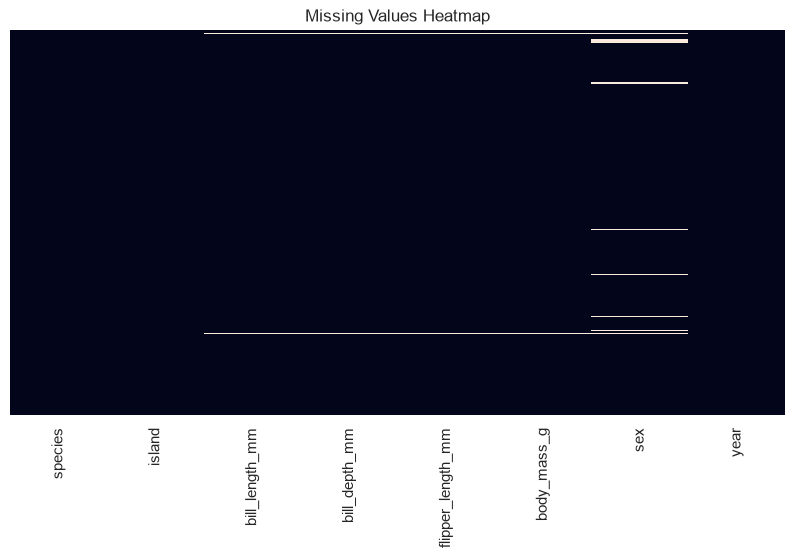

In [9]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values Heatmap")
plt.show()

## 4. Duplicate Values

We check whether the dataset contains duplicated rows.


In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## 5. Numerical Feature Distributions

Histograms help us understand the distribution of numerical features.

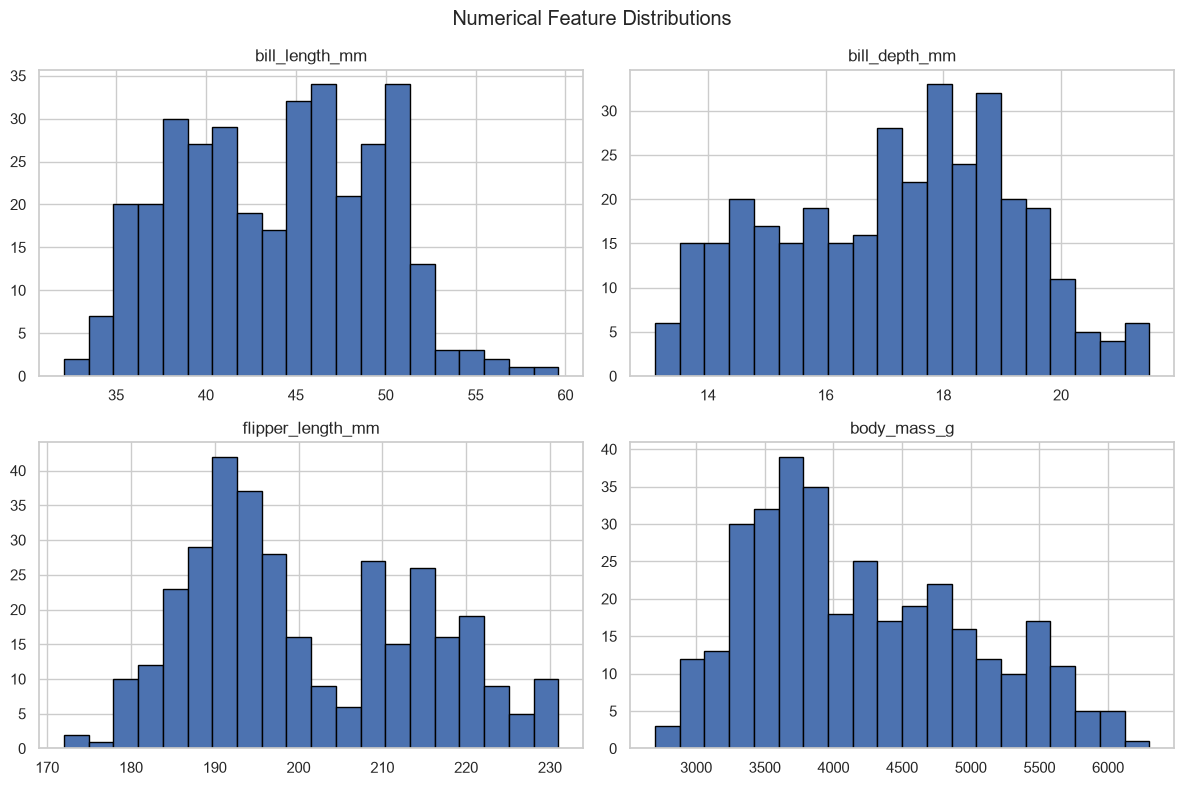

In [11]:
numerical_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

df[numerical_columns].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

## 6. Outlier Detection

Boxplots and the IQR method help identify possible outliers.

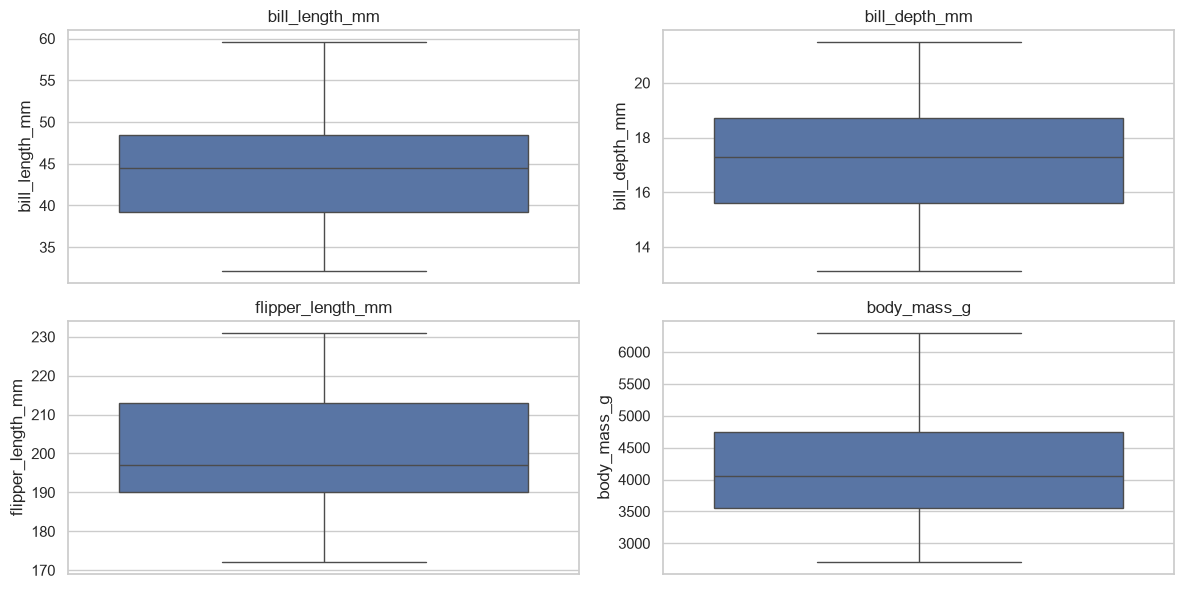

In [12]:
plt.figure(figsize=(12, 6))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [13]:
for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower) | (df[column] > upper)
    ]

    print(column, "- possible outliers:", len(outliers))

bill_length_mm - possible outliers: 0
bill_depth_mm - possible outliers: 0
flipper_length_mm - possible outliers: 0
body_mass_g - possible outliers: 0


Outliers are not automatically errors. In this dataset, unusual measurements may represent natural differences between penguin species.

## 7. Categorical Feature Analysis

We examine the frequency of categories.

In [14]:
categorical_columns = ["species", "island", "sex"]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

island:
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

sex:
sex
male      168
female    165
NaN        11
Name: count, dtype: int64


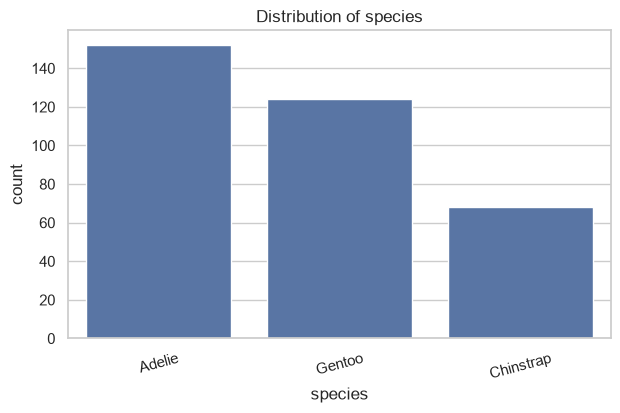

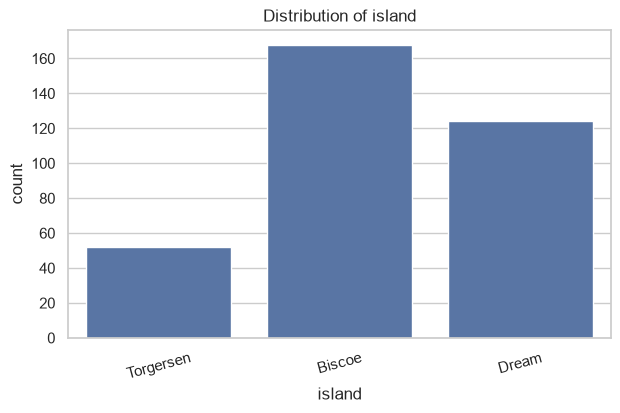

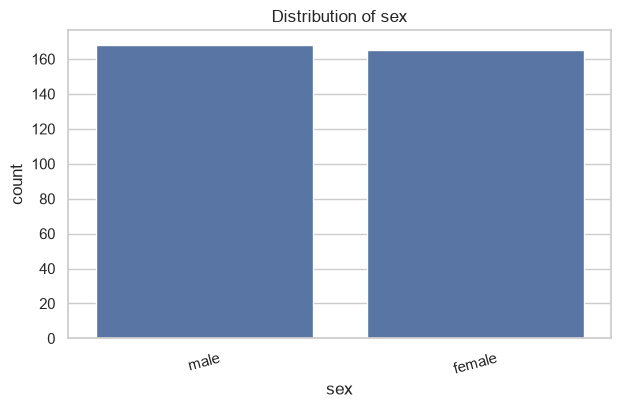

In [15]:
for column in categorical_columns:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=column)
    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=15)
    plt.show()

## 8. Correlation Analysis

We analyze relationships between numerical features using correlation coefficients.

In [16]:
correlation = df[numerical_columns].corr()

correlation

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000000,-0.235053,0.656181,0.595110
bill_depth_mm,-0.235053,1.000000,-0.583851,-0.471916
flipper_length_mm,0.656181,-0.583851,1.000000,0.871202
body_mass_g,0.595110,-0.471916,0.871202,1.000000


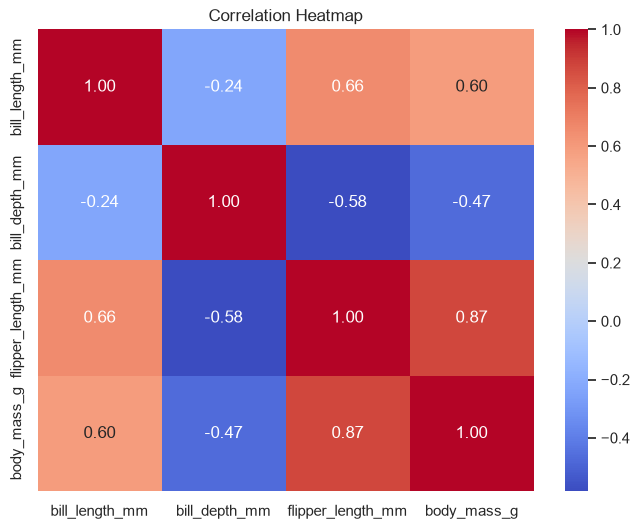

In [17]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [18]:
pairs = []

for i in range(len(numerical_columns)):
    for j in range(i + 1, len(numerical_columns)):
        col1 = numerical_columns[i]
        col2 = numerical_columns[j]

        pairs.append((
            col1,
            col2,
            correlation.loc[col1, col2]
        ))

pairs = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)

for col1, col2, value in pairs:
    print(f"{col1} - {col2}: {value:.3f}")

flipper_length_mm - body_mass_g: 0.871
bill_length_mm - flipper_length_mm: 0.656
bill_length_mm - body_mass_g: 0.595
bill_depth_mm - flipper_length_mm: -0.584
bill_depth_mm - body_mass_g: -0.472
bill_length_mm - bill_depth_mm: -0.235


## 9. Relationships Between Features

Scatterplots help visualize relationships between numerical features and species.

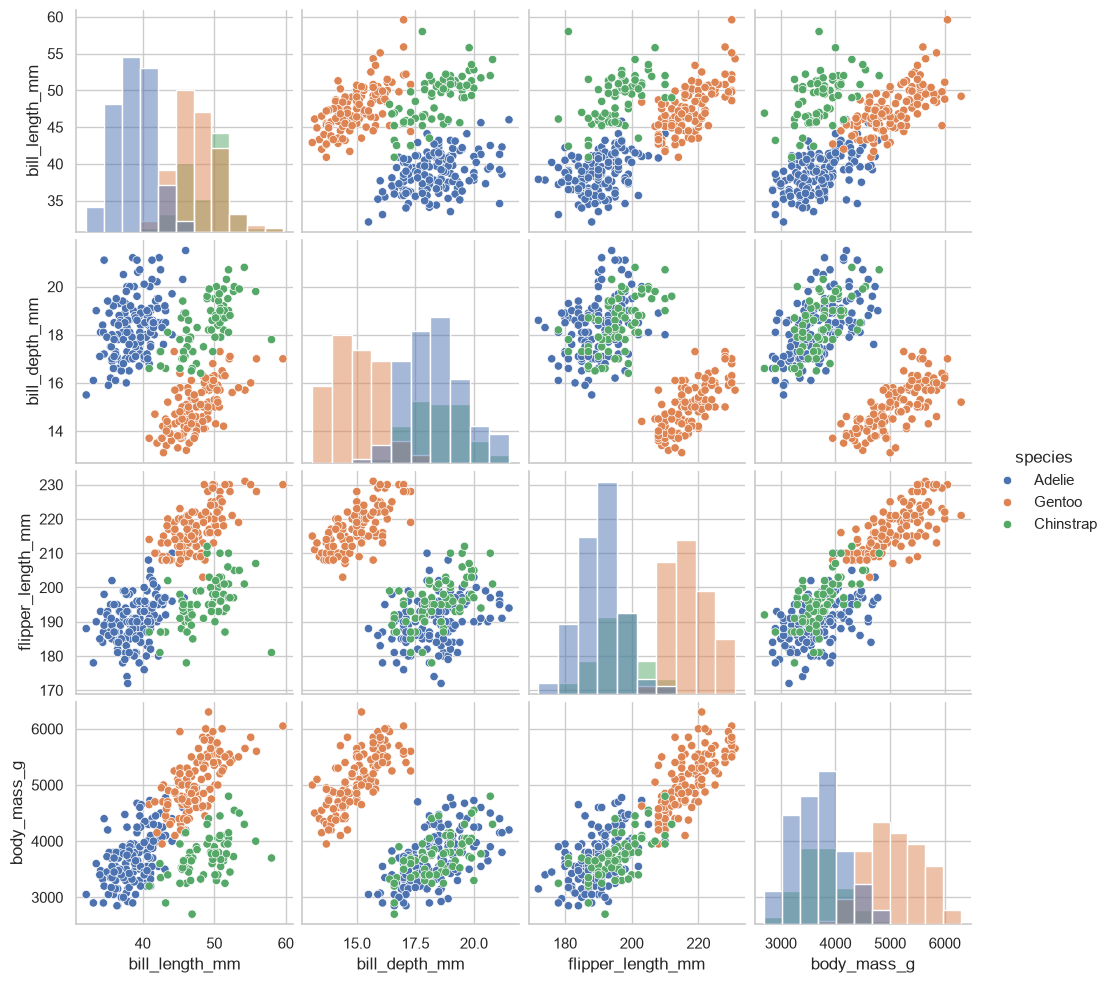

In [19]:
sns.pairplot(
    df,
    vars=numerical_columns,
    hue="species",
    diag_kind="hist"
)

plt.show()

## 10. Target Variable Analysis

The target variable is species. We examine the number and percentage of observations in each class.

In [20]:
print("Species counts:")
print(df["species"].value_counts())

print("\nSpecies percentages:")
print((df["species"].value_counts(normalize=True) * 100).round(2))

Species counts:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Species percentages:
species
Adelie       44.19
Gentoo       36.05
Chinstrap    19.77
Name: proportion, dtype: float64


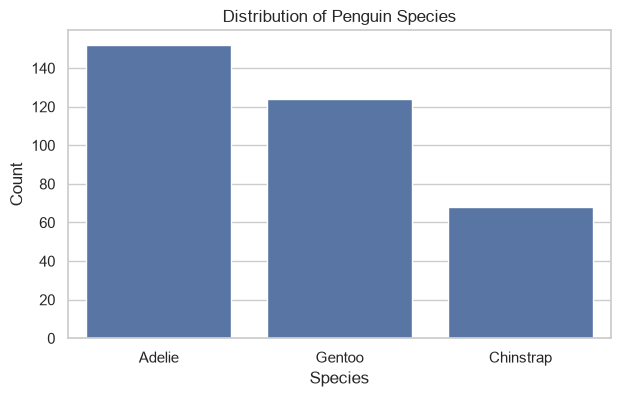

In [21]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="species")

plt.title("Distribution of Penguin Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

## 11. Conclusion

During this exploratory data analysis:

1. The dataset contains 344 observations and 8 columns.
2. Numerical and categorical features were identified.
3. Missing values were examined.
4. Duplicate records were checked.
5. Numerical feature distributions were visualized.
6. Possible outliers were detected using the IQR method.
7. Categorical features and species distribution were analyzed.
8. Correlations between numerical features were examined.
9. Relationships between numerical features and species were visualized.

The analysis helped us understand the structure, quality and relationships in the Palmer Penguins dataset.